# **FLIGHT PRICE PREDICTION — LINEAR REGRESSION**
Dataset: `Dataset.csv` (flight tickets between 6 Indian cities).

The user enters **boarding point, dropping point, time of flight** (Early_Morning / Morning / Afternoon / Evening / Night / Late_Night), **class** and **how many days before** the flight they are booking. The trained model then **predicts the ticket price** and shows graphs.

Only concepts from **Practice Lab 7 (Linear Regression)** are used: pandas, numpy, matplotlib, `train_test_split`, `Pipeline` + `SimpleImputer` + `OneHotEncoder` + `ColumnTransformer`, `LinearRegression`, and MAE / MSE / RMSE / R².

$$\hat{y} = b_0 + b_1x_1 + b_2x_2 + \cdots + b_nx_n$$
$\hat{y}$ = predicted price; $x_1, x_2, \ldots$ = source city, destination city, departure time, class, days left.

### 1. Import Libraries

In [2]:
import pandas as pd                  # Read and work with tabular data
import numpy as np                   # Numerical operations
import matplotlib.pyplot as plt      # Graphs and visualizations

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Display graphs inside the notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


### 2. Read Dataset

In [3]:
df = pd.read_csv('data/Dataset.csv')   # change the path if your file is elsewhere
print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (50000, 11)


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,Air_India,AI-506,Delhi,Morning,one,Early_Morning,Kolkata,Economy,19.75,40,7366
1,Vistara,UK-706,Kolkata,Morning,one,Night,Mumbai,Business,9.83,42,64831
2,Vistara,UK-772,Kolkata,Morning,one,Night,Bangalore,Economy,10.50,41,6195
3,Vistara,UK-824,Chennai,Night,one,Morning,Delhi,Business,14.50,14,60160
4,Air_India,AI-501,Bangalore,Afternoon,one,Night,Mumbai,Economy,8.25,20,6578


### 3. Understand the dataset
- `shape`, `head()`, `tail()`, `info()`, `describe()`, `isnull().sum()`

In [4]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nLast ten rows:")
display(df.tail(10))

print("\nData types and missing-value overview:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nSummary of numeric columns:")
display(df.describe())

Dataset dimensions: (50000, 11)

Column names:
['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']

First five rows:


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,Air_India,AI-506,Delhi,Morning,one,Early_Morning,Kolkata,Economy,19.75,40,7366
1,Vistara,UK-706,Kolkata,Morning,one,Night,Mumbai,Business,9.83,42,64831
2,Vistara,UK-772,Kolkata,Morning,one,Night,Bangalore,Economy,10.50,41,6195
3,Vistara,UK-824,Chennai,Night,one,Morning,Delhi,Business,14.50,14,60160
4,Air_India,AI-501,Bangalore,Afternoon,one,Night,Mumbai,Economy,8.25,20,6578



Last ten rows:


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
49990,Vistara,UK-708,Kolkata,Night,one,Night,Bangalore,Economy,26.92,17,8111
49991,Indigo,6E-6488,Kolkata,Morning,one,Night,Hyderabad,Economy,8.67,38,8747
49992,Air_India,AI-543,Hyderabad,Morning,one,Night,Mumbai,Economy,9.92,11,7774
49993,Indigo,6E-5001,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.17,43,2410
49994,AirAsia,I5-1426,Bangalore,Afternoon,one,Late_Night,Delhi,Economy,12.00,29,2723
49995,Air_India,AI-663,Mumbai,Afternoon,one,Late_Night,Delhi,Economy,14.25,39,5828
49996,GO_FIRST,G8-717,Delhi,Evening,one,Morning,Kolkata,Economy,16.00,13,5954
49997,Vistara,UK-996,Mumbai,Evening,one,Morning,Bangalore,Business,16.33,41,85744
49998,GO_FIRST,G8-116,Bangalore,Early_Morning,one,Night,Kolkata,Economy,14.42,35,7978
49999,Indigo,6E-2348,Delhi,Evening,one,Late_Night,Bangalore,Economy,5.58,29,3671



Data types and missing-value overview:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   airline           50000 non-null  str    
 1   flight            50000 non-null  str    
 2   source_city       50000 non-null  str    
 3   departure_time    50000 non-null  str    
 4   stops             50000 non-null  str    
 5   arrival_time      50000 non-null  str    
 6   destination_city  50000 non-null  str    
 7   class             50000 non-null  str    
 8   duration          50000 non-null  float64
 9   days_left         50000 non-null  int64  
 10  price             50000 non-null  int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 4.2 MB

Missing values in each column:
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class  

,duration,days_left,price
count,50000.000000,50000.000000,50000.000000
mean,12.245605,26.012500,20827.466020
std,7.179290,13.531321,22658.672268
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4784.000000
50%,11.250000,26.000000,7424.000000
75%,16.170000,38.000000,42521.000000
max,47.750000,49.000000,114705.000000


### 4. Explore the data with graphs
Histogram of price, scatter plot of days left vs price, and a bar chart of the average price for each departure time.

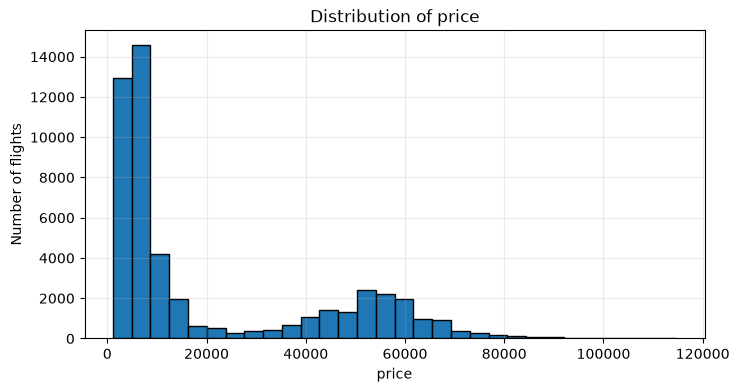

In [5]:
# Histogram of the target column
plt.figure(figsize=(8, 4))
plt.hist(df["price"].dropna(), bins=30, edgecolor="black")
plt.title("Distribution of price")
plt.xlabel("price")
plt.ylabel("Number of flights")
plt.grid(alpha=0.25)
plt.show()

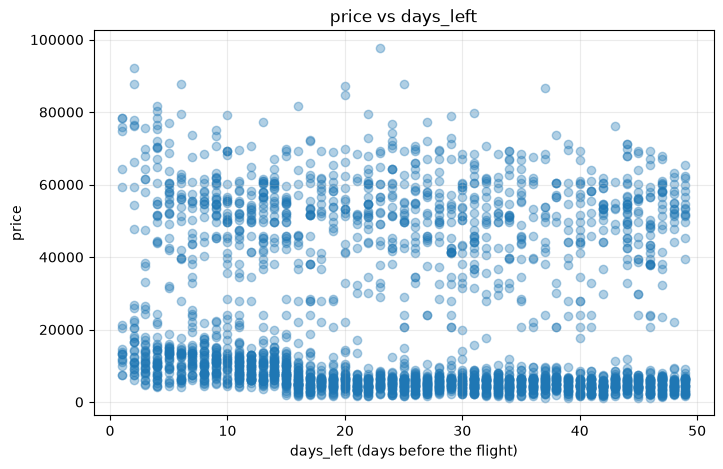

In [6]:
# Scatter plot: days_left vs price (a random sample keeps the plot readable)
sample = df.sample(n=min(3000, len(df)), random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(sample["days_left"], sample["price"], alpha=0.35)
plt.title("price vs days_left")
plt.xlabel("days_left (days before the flight)")
plt.ylabel("price")
plt.grid(alpha=0.25)
plt.show()

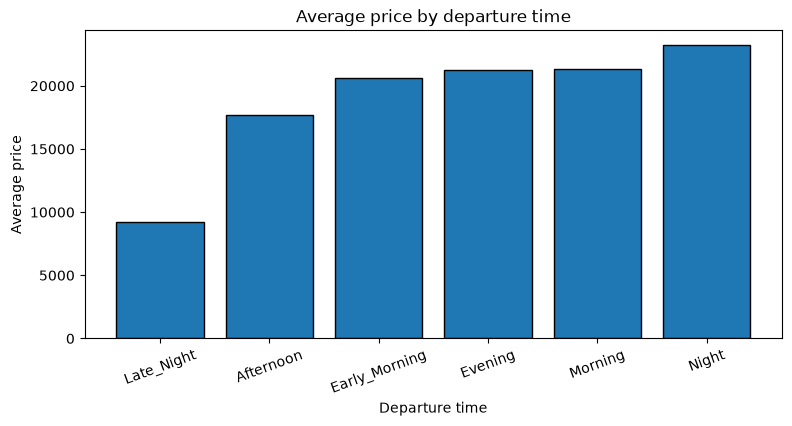

In [7]:
# Bar chart: average price for each departure time
avg_by_time = df.groupby("departure_time")["price"].mean().sort_values()

plt.figure(figsize=(9, 4))
plt.bar(avg_by_time.index, avg_by_time.values, edgecolor="black")
plt.title("Average price by departure time")
plt.xlabel("Departure time")
plt.ylabel("Average price")
plt.xticks(rotation=20)
plt.show()

### 5. Preprocess the data
1. Remove duplicate rows.
2. Select the target (`price`) and the input features — the same things the user will enter later.
3. Fill missing numeric values with the median, missing categories with the most frequent value.
4. One-hot encode the categorical columns.



In [8]:
df = df.drop_duplicates().copy()

print("Available columns:", df.columns.tolist())

# Target (what we want to predict)
target_column = "price"

# Input features = what the user will enter
feature_columns = [
    "source_city", "destination_city", "departure_time",
    "class", "days_left"
]

# Validate column names
missing_columns = [
    col for col in [target_column] + feature_columns
    if col not in df.columns
]

if missing_columns:
    print("Error: These columns do not exist:", missing_columns)
else:
    print("Target:", target_column)
    print("Features:", feature_columns)
    display(df[[target_column] + feature_columns].head())

Available columns: ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']
Target: price
Features: ['source_city', 'destination_city', 'departure_time', 'class', 'days_left']


,price,source_city,destination_city,departure_time,class,days_left
0,7366,Delhi,Kolkata,Morning,Economy,40
1,64831,Kolkata,Mumbai,Morning,Business,42
2,6195,Kolkata,Bangalore,Morning,Economy,41
3,60160,Chennai,Delhi,Night,Business,14
4,6578,Bangalore,Mumbai,Afternoon,Economy,20


In [9]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Keep only selected features and target
model_df = df[feature_columns + [target_column]].copy()

# Convert the target to numeric; non-numeric values become NaN
model_df[target_column] = pd.to_numeric(model_df[target_column], errors="coerce")

# Remove rows where the target price is missing or invalid
model_df = model_df.dropna(subset=[target_column])

X = model_df[feature_columns]
y = model_df[target_column]

# Detect numeric and categorical input columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Fill missing numeric values with median
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Fill missing categories with the most frequent category, then encode them
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each column type
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Rows available for modelling:", len(model_df))

Input shape: (50000, 5)
Target shape: (50000,)
Numeric features: ['days_left']
Categorical features: ['source_city', 'destination_city', 'departure_time', 'class']
Rows available for modelling: 50000


### 6. Split into training and testing data (80% / 20%)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 40000
Testing examples: 10000


### 7. Build and train the Linear Regression model

In [11]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


### 8. Make predictions on the test set

In [12]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred,
    "Error (Actual - Predicted)": y_test.to_numpy() - y_pred
})

display(comparison.head(10))

,Actual Price,Predicted Price,Error (Actual - Predicted)
0,5352,7723.148904,-2371.148904
1,9433,7827.453225,1605.546775
2,14301,12033.910366,2267.089634
3,8719,5173.487979,3545.512021
4,56273,50688.737171,5584.262829
5,3999,8417.441347,-4418.441347
6,2464,2891.124753,-427.124753
7,6172,2877.183213,3294.816787
8,52586,50649.704903,1936.295097
9,3987,4567.991907,-580.991907


### 9. Evaluate the model
MAE, MSE, RMSE (same units as price, lower is better) and R² (closer to 1 is better).

In [13]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:,.3f}")
print(f"MSE  : {mse:,.3f}")
print(f"RMSE : {rmse:,.3f}")
print(f"R²   : {r2:.3f}")

MAE  : 4,673.923
MSE  : 57,116,355.103
RMSE : 7,557.536
R²   : 0.890


### 10. Actual vs predicted prices

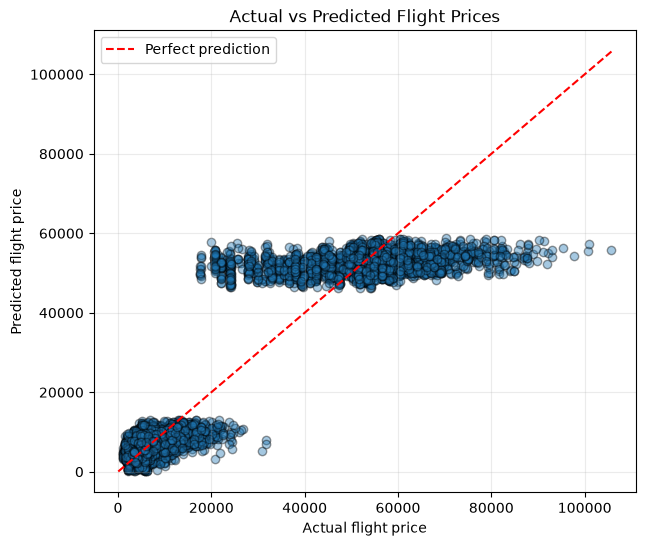

In [14]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.4, edgecolor="black")

# Reference line from the smallest to largest value
low = min(float(np.min(y_test)), float(np.min(y_pred)))
high = max(float(np.max(y_test)), float(np.max(y_pred)))
plt.plot([low, high], [low, high], linestyle="--", color="red", label="Perfect prediction")

plt.xlabel("Actual flight price")
plt.ylabel("Predicted flight price")
plt.title("Actual vs Predicted Flight Prices")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 11. Five largest prediction errors

In [15]:
comparison["Absolute Error"] = comparison["Error (Actual - Predicted)"].abs()
display(comparison.nlargest(5, "Absolute Error"))

,Actual Price,Predicted Price,Error (Actual - Predicted),Absolute Error
8038,105744,55717.774673,50026.225327,50026.225327
4750,100671,55536.461633,45134.538367,45134.538367
5163,100909,57425.139064,43483.860936,43483.860936
39,97681,54300.060151,43380.939849,43380.939849
9817,92027,52243.026347,39783.973653,39783.973653


### 12. Predict the price for the user's flight
The user chooses the **boarding point**, **dropping point**, **time of flight**, **class** and **how many days before** the flight they are booking. Valid options are taken from the dataset itself, and the input is checked before predicting.

In [17]:
# Valid options (taken from the dataset)
cities = sorted(df["source_city"].unique())
times = list(df["departure_time"].unique())
classes = list(df["class"].unique())

print("Cities        :", cities)
print("Time of flight:", times)
print("Class         :", classes)

def ask(question, options):
    # Keep asking until the user types one of the valid options
    while True:
        answer = input(question + " " + str(options) + ": ").strip()
        for option in options:
            if answer.lower() == option.lower():
                return option
        print("Invalid choice, please type one of the options shown.")

user_source = ask("Boarding point", cities)
user_dest = ask("Dropping point", cities)
while user_dest == user_source:
    print("Boarding and dropping point cannot be the same.")
    user_dest = ask("Dropping point", cities)

user_time = ask("Time of flight", times)
user_class = ask("Class", classes)

while True:
    days_text = input("Days before the flight you are booking (1 to 49): ").strip()
    if days_text.isdigit() and 1 <= int(days_text) <= 49:
        user_days = int(days_text)
        break
    print("Please enter a whole number between 1 and 49.")

# One row with the SAME feature columns used during training
user_flight = pd.DataFrame({
    "source_city": [user_source],
    "destination_city": [user_dest],
    "departure_time": [user_time],
    "class": [user_class],
    "days_left": [user_days]
})

predicted_price = model.predict(user_flight)[0]

print("\n----- FLIGHT DETAILS -----")
print("From          :", user_source)
print("To            :", user_dest)
print("Time of flight:", user_time)
print("Class         :", user_class)
print("Booking       :", user_days, "days before the flight")
print(f"\nPredicted Flight Price: Rs. {predicted_price:,.0f}")

Cities        : ['Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai']
Time of flight: ['Morning', 'Night', 'Afternoon', 'Early_Morning', 'Evening', 'Late_Night']
Class         : ['Economy', 'Business']

----- FLIGHT DETAILS -----
From          : Delhi
To            : Kolkata
Time of flight: Evening
Class         : Business
Booking       : 15 days before the flight

Predicted Flight Price: Rs. 54,085


### 13. Graphs for the user's flight
1. How the predicted price changes with the number of days before booking.
2. The predicted price for each time of flight on the same route.

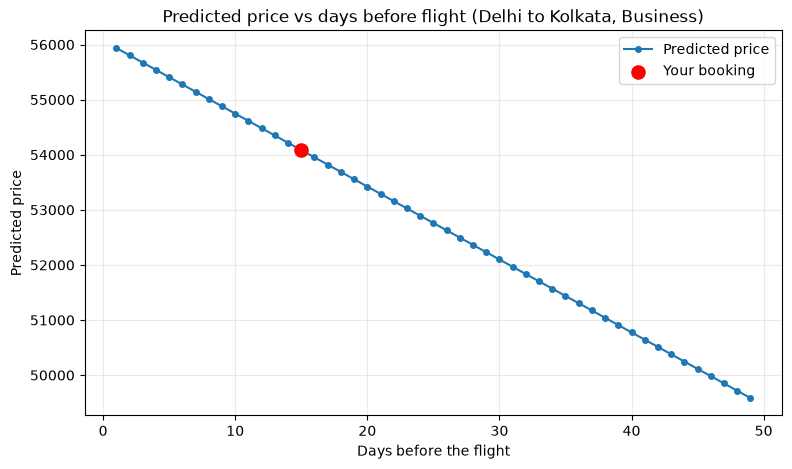

In [18]:
# Graph 1: predicted price for 1 to 49 days before the flight
days_range = np.arange(1, 50)

days_df = pd.DataFrame({
    "source_city": user_source,
    "destination_city": user_dest,
    "departure_time": user_time,
    "class": user_class,
    "days_left": days_range
})
days_pred = model.predict(days_df)

plt.figure(figsize=(9, 5))
plt.plot(days_range, days_pred, marker="o", markersize=4, label="Predicted price")
plt.scatter([user_days], [predicted_price], color="red", s=90, zorder=5, label="Your booking")
plt.title(f"Predicted price vs days before flight ({user_source} to {user_dest}, {user_class})")
plt.xlabel("Days before the flight")
plt.ylabel("Predicted price")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

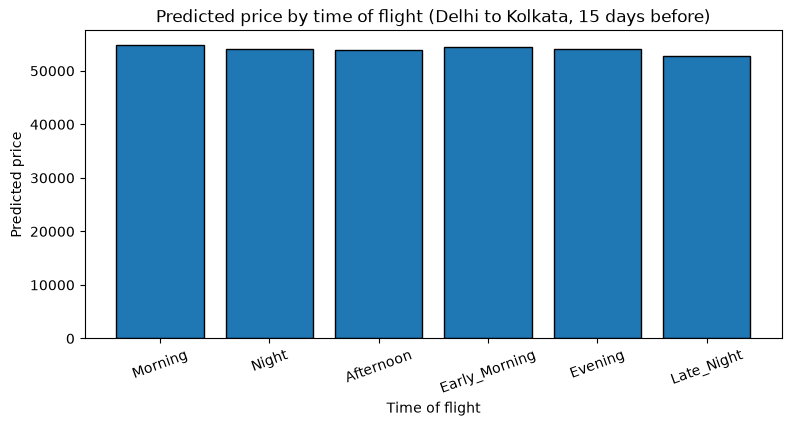

Cheapest time of flight for this route: Late_Night


In [19]:
# Graph 2: predicted price for every time of flight (same route, class and days left)
time_df = pd.DataFrame({
    "source_city": user_source,
    "destination_city": user_dest,
    "departure_time": times,
    "class": user_class,
    "days_left": user_days
})
time_pred = model.predict(time_df)

plt.figure(figsize=(9, 4))
plt.bar(times, time_pred, edgecolor="black")
plt.title(f"Predicted price by time of flight ({user_source} to {user_dest}, {user_days} days before)")
plt.xlabel("Time of flight")
plt.ylabel("Predicted price")
plt.xticks(rotation=20)
plt.show()

cheapest = times[int(np.argmin(time_pred))]
print("Cheapest time of flight for this route:", cheapest)